In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import pickle
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import foldnorm
import os

plt.rcParams.update(
    {
        "text.usetex": False,
        "font.family": "serif",
        "mathtext.fontset": "cm",
    }
)

In [2]:
theoretical_dir = "../Theoretical_Results"
theoretical_results_file = os.path.join(
    theoretical_dir, "theoretical_transpilation_results.csv"
)
df_theoretical = pd.read_csv(theoretical_results_file)

In [3]:
n_qubits = 3
optimization_levels = [0, 1, 2, 3]
colors = ["#0072B2", "#009E73", "#56B4E9", "#D55E00"]
colors = {
    0: colors[0],
    1: colors[1],
    2: colors[2],
    3: colors[3],
}
worst_observable_index = 1  # corresponds to the observable having the worst performance over all transpilations
optimization_handles = [
    Patch(color=colors[optimization_level], label=optimization_level)
    for optimization_level in optimization_levels
]

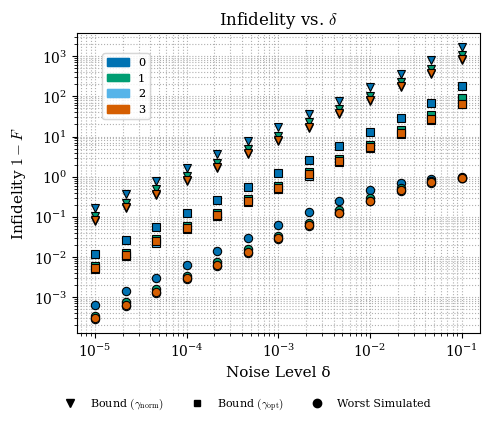

In [5]:
fig, ax = plt.subplots(figsize=(5, 4))
style_handles = [
    Line2D(
            [0],
            [0],
            color="black",
            marker="v",
            linestyle="none",
            label="Bound $(\gamma_{\mathrm{norm}})$",
        ),
    Line2D(
        [0],
        [0],
        marker="s",
        linestyle="none",
        color="black",
        markersize=5,
        label="Bound $(\gamma_{\mathrm{opt}})$",
    ),
    Line2D(
        [0],
        [0],
        color="black",
        marker="o",
        linestyle="none",
        label="Worst Simulated",
    ),
]
for optimization_level in optimization_levels:
    df_subset_optimization_level = df_theoretical[df_theoretical["optimization_level"] == optimization_level]
    color = colors[optimization_level]
    ax.plot(
        df_subset_optimization_level["delta"],
        df_subset_optimization_level["worst_case_infidelity_bound_b2"],
        label = optimization_level,
        marker = "s",
        linestyle="",
        markerfacecolor = color,
        markeredgecolor = "black",
        markeredgewidth = 0.8,
    )
    ax.plot(
        df_subset_optimization_level["delta"],
        df_subset_optimization_level["worst_case_infidelity_bound_b4"],
        label = optimization_level,
        marker = "v",
        linestyle="",
        markerfacecolor = color,
        markeredgecolor = "black",
        markeredgewidth = 0.8,
    )
    ax.plot(
        df_subset_optimization_level["delta"],
        df_subset_optimization_level["worst_infidelity_simulated"],
        label = optimization_level,
        marker = "o",
        linestyle="",
        markerfacecolor = color,
        markeredgecolor = "black",
        markeredgewidth = 0.8,
    )
legend1 = ax.legend(
    handles=optimization_handles,
    loc="upper left",
    bbox_to_anchor = (0.05, 0.95),
    fontsize=8,
    framealpha=0.6,
)
legend = fig.legend(
    handles=style_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.07),
    ncol=3,
    fontsize=8,
    frameon=False,
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Noise Level δ", fontsize=11)
ax.set_ylabel("Infidelity $1-F$", fontsize=11)
ax.set_title(rf"Infidelity vs. $\delta$", fontsize=12)
# ax.set_xlim(left=1e-5, right=1e-2)
# ax.set_ylim(bottom=1e-10, top=1e-1)
ax.grid(True, which="both", ls=":")
ax.add_artist(legend1)
plt.tight_layout()
plt.savefig(f"QFT_Infidelity_vs_Delta_transpilations.pdf")


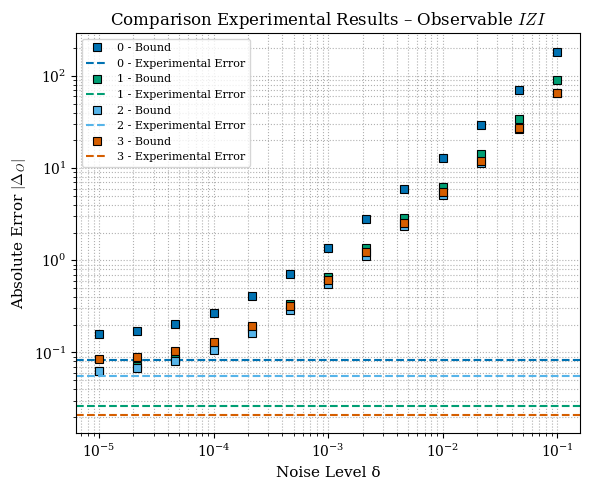

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
for optimization_level in optimization_levels:
    experimental_data_dir = f"../Experimental_Data/qft_{n_qubits}_ibm_fez_{optimization_level}"
    with open(os.path.join(experimental_data_dir, "results.pkl"), "rb") as f:
        experimental_results = pickle.load(f)
    df_subset_optimization_level = df_theoretical[df_theoretical["optimization_level"] == optimization_level]
    color = colors[optimization_level]
    ax.plot(
        df_subset_optimization_level["delta"],
        df_subset_optimization_level["worst_case_observable_bound_b2"],
        label = f"{optimization_level} - Bound",
        marker = "s",
        linestyle="",
        markerfacecolor = color,
        markeredgecolor = "black",
        markeredgewidth = 0.8,
    )
    absolute_error = experimental_results["hardware"]["observable_difference"][worst_observable_index]
    ax.axhline(
        absolute_error,
        label = f"{optimization_level} - Experimental Error",
        color = color,
        linestyle = "dashed",
    )
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Noise Level δ", fontsize=11)
ax.set_ylabel("Absolute Error $|\Delta_O|$", fontsize=11)
ax.set_title(rf"Comparison Experimental Results – Observable $IZI$", fontsize=12)
# ax.set_xlim(left=1e-5, right=1e-2)
# ax.set_ylim(bottom=1e-10, top=1e-1)
ax.grid(True, which="both", ls=":")
ax.legend(fontsize=8, ncol=1)
plt.tight_layout()
plt.savefig(f"QFT_Experimental_Results_Transpilations.pdf")
